In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# Data quality analysis
We load the **raw** extract (including deliberately injected defects), run the validation suite, then show what cleaning did.

In [2]:
from src.preprocessing.validation import validate_transactions, validation_pass_rate
from src.preprocessing.cleaning import clean_transactions
raw = load_raw()
checks = pd.DataFrame(validate_transactions(raw, CFG)); checks

,check,passed,failed_count,total,detail
0,schema_columns_present,True,0,16,
1,min_rows,True,0,1,rows=60120
2,missing_ratio_within_limit,True,0,1,0.4025%
3,no_missing_amount,False,242,60120,
4,duplicate_ratio_within_limit,True,0,1,0.1996%
5,no_duplicate_transaction_id,False,120,60120,
6,amount_positive,False,78,60120,
7,timestamp_parsable,True,0,60120,
8,ip_risk_in_unit_interval,True,0,60120,
9,label_is_binary,True,0,60120,


In [3]:
print('pass rate:', round(validation_pass_rate(checks.to_dict('records')), 3))
checks[~checks.passed][['check','failed_count','detail']]

pass rate: 0.769


,check,failed_count,detail
3,no_missing_amount,242,
5,no_duplicate_transaction_id,120,
6,amount_positive,78,


In [4]:
clean, rep = clean_transactions(raw); pd.Series(rep).to_frame('rows')

,rows
rows_in,60120
duplicates_removed,120
invalid_removed,318
rows_out,59682


In [5]:
after = pd.DataFrame(validate_transactions(clean, CFG))
pd.concat([checks.set_index('check').failed_count.rename('before'), after.set_index('check').failed_count.rename('after')], axis=1)

,before,after
check,,
schema_columns_present,0,0
min_rows,0,0
missing_ratio_within_limit,0,0
no_missing_amount,242,0
duplicate_ratio_within_limit,0,0
no_duplicate_transaction_id,120,0
amount_positive,78,0
timestamp_parsable,0,0
ip_risk_in_unit_interval,0,0


[Text(0.5, 1.0, 'Missing values in raw data (%)')]

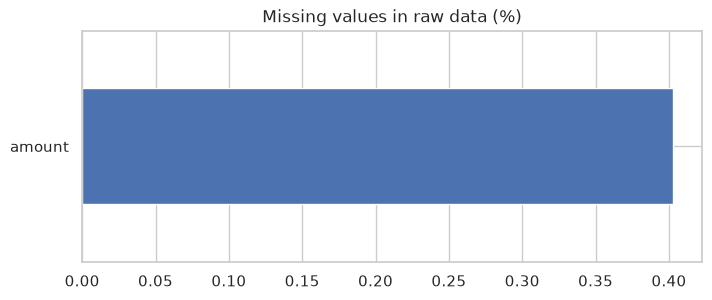

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
raw.isna().mean().mul(100).loc[lambda s: s > 0].plot.barh(ax=ax); ax.set(title='Missing values in raw data (%)')

Residual `fraud_pattern`/label columns are retained for analysis only; they are **never** model features (see `feature_names()`).